#### Definição das variáveis de interesse da separação por perfil de município

1. Eliminação de Multicolinearidade

2. Análise de Componentes Principais (PCA)

3. Selecionar os mais fortes no ranking da PCA 

In [51]:
from pathlib import Path
import pandas as pd

base_path = Path.cwd().parent
file_path = base_path / "data" / "processed" / "Base_de_Dados_Processada.csv"

df = pd.read_csv(file_path)

df.head()

,População_2022,Pontuação Indice ODS 2025,Goal 1 Score,Goal 2 Score,Goal 3 Score,Goal 5 Score,Goal 6 Score,Goal 7 Score,Goal 8 Score,Goal 9 Score,...,SDG16_CRP,Normalizado (0-100): SDG16_CRP,SDG16_DRTHMN,Normalizado (0-100): SDG16_DRTHMN,SDG16_TRANSP,Normalizado (0-100): SDG16_TRANSP,SDG17_1_INVST_PB,Normalizado (0-100): SDG17_1_INVST_PB,SDG17_3_P_RC_TRB,Normalizado (0-100): SDG17_3_P_RC_TRB
0,21495.0,41.885064,53.769451,53.255278,66.451721,58.730307,20.177142,56.309444,46.940699,11.631238,...,85.714,85.714,42.857,42.857,66.667,66.667,13.216,0.000000,5.257,8.108054
1,96833.0,45.475390,54.219225,50.890756,65.677811,41.654565,72.408554,68.007222,49.281375,14.603964,...,85.714,85.714,57.143,57.143,66.667,66.667,85.642,1.133196,18.394,34.298246
2,5363.0,47.569518,49.228293,43.817398,89.494428,48.938353,44.025511,63.241944,54.613778,7.181381,...,85.714,85.714,42.857,42.857,66.667,66.667,909.852,38.715329,5.686,8.963317
3,86895.0,48.582323,50.752090,51.083977,73.026011,47.023041,66.630268,69.962222,45.581682,17.049953,...,85.714,85.714,57.143,57.143,50.000,50.000,328.073,12.187507,21.627,40.743620
4,15890.0,48.718897,56.552994,50.268036,79.958615,32.086768,65.794541,68.762222,52.890151,11.397874,...,100.000,100.000,42.857,42.857,66.667,66.667,246.352,8.461212,12.178,21.905901


In [52]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print(f"Tamanho treino: {df_train.shape[0]} municípios")
print(f"Tamanho teste: {df_test.shape[0]} municípios")

Tamanho treino: 4456 municípios
Tamanho teste: 1114 municípios


- Cálculo de correlação média de cada variável com relação a toda a base 
- Para cada par com correlação > 0.80, descarta a variável mais redundante do par, ou seja a que contém a maior correlação média com o restante, em vez de simplesmente a que aparece primeiro na ordem das colunas do DataFrame

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

cols_to_keep = [c for c in df_train.columns if c.startswith('SDG') 
                and 'SDG4' not in c 
                and 'IDEB' not in c ]

df_model = df_train[cols_to_keep].copy()

corr_matrix = df_model.corr().abs()

mean_corr = corr_matrix.mean()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = set()
pairs_above_threshold = []

for column in upper.columns:
    correlated = upper.index[upper[column] > 0.80].tolist()
    for row in correlated:
        pairs_above_threshold.append((column, row))
        loser = column if mean_corr[column] >= mean_corr[row] else row
        to_drop.add(loser)

X_filtered = df_model.drop(columns=list(to_drop))

print(f"Total de variáveis iniciais: {len(df_model.columns)}")
print(f"Pares com correlação > 0.80 encontrados: {len(pairs_above_threshold)}")
print(f"Total após remover redundantes (Correlação > 0.8): {len(X_filtered.columns)}")
print("\nVariáveis descartadas por multicolinearidade (e sua correlação média com as demais):")

for v in sorted(to_drop):
    print(f"  - {v}: {mean_corr[v]:.3f}")


Total de variáveis iniciais: 85
Pares com correlação > 0.80 encontrados: 8
Total após remover redundantes (Correlação > 0.8): 77

Variáveis descartadas por multicolinearidade (e sua correlação média com as demais):
  - SDG10_1_PREN20: 0.219
  - SDG11_4_P_P_SUBN: 0.110
  - SDG16_4_TX_HMC: 0.132
  - SDG1_3_COBBF: 0.245
  - SDG3_15_T_M_INF: 0.079
  - SDG3_17_T_M_5A: 0.081
  - SDG8_3_T_DSC: 0.158
  - SDG8_7_P_JV_NENT: 0.219


#### Aplicação da análise de componentes principais 

In [54]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filtered)

# 5 principais (a definir)
pca = PCA(n_components=5) 
pca.fit(X_scaled)

# Extração da importância de cada vartiável 
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'], index=X_filtered.columns)

#### Escolha do número de componentes 

em vez de fixar `n_components=5` arbitrariamente

Uma estratégia é quanta variância cada componente explica e usar um critério objetivo (Kaiser ou % de variância acumulada) para decidir quantos manter.


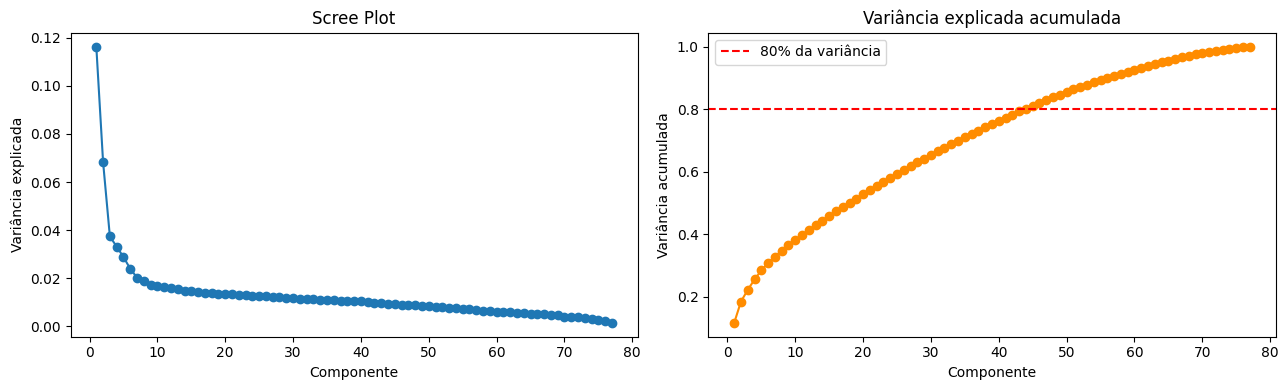

Critério de Kaiser (autovalor > 1): 22 componentes
Componentes necessários para explicar >= 80% da variância: 44

Com n_components=5 (valor atual do notebook), a variância explicada acumulada é 28.4%


In [55]:
# Verificação do número de componentes
pca_full = PCA().fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
eigenvalues = pca_full.explained_variance_

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(range(1, len(explained) + 1), explained, 'o-')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Variância explicada')
axes[0].set_title('Scree Plot')

axes[1].plot(range(1, len(cumulative) + 1), cumulative, 'o-', color='darkorange')
axes[1].axhline(y=0.80, color='red', linestyle='--', label='80% da variância')
axes[1].set_xlabel('Componente')
axes[1].set_ylabel('Variância acumulada')
axes[1].set_title('Variância explicada acumulada')
axes[1].legend()

plt.tight_layout()
plt.show()

n_kaiser = int((eigenvalues > 1).sum())
n_80pct = int(np.argmax(cumulative >= 0.80) + 1)

print(f"Critério de Kaiser (autovalor > 1): {n_kaiser} componentes")
print(f"Componentes necessários para explicar >= 80% da variância: {n_80pct}")
print(f"\nCom n_components=5 (valor atual do notebook), a variância explicada acumulada é "
      f"{cumulative[4]*100:.1f}%")


In [56]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filtered)

# n_components alterado de 5 para 22, seguindo o critério de Kaiser (autovalor > 1)
# identificado na célula de scree plot
pca = PCA(n_components=22) 
pca.fit(X_scaled)

# Extração da importância de cada variável (colunas geradas dinamicamente
pc_columns = [f'PC{i}' for i in range(1, pca.n_components_ + 1)]
loadings = pd.DataFrame(pca.components_.T, columns=pc_columns, index=X_filtered.columns)

#### Checagem de sobreposição entre eixos e consolidação do subconjunto final


In [57]:
# Checagem de sobreposição entre as variáveis selecionadas nos diferentes eixos
top_n = 1  # reduzido de 3 para 1 -- com 22 eixos, top_n=3 gerava pouca redução real
           # de dimensionalidade (77 -> 46); com top_n=1, o teto passa a ser 22
selected_by_pc = {
    pc: loadings[pc].abs().sort_values(ascending=False).head(top_n).index.tolist()
    for pc in pc_columns
}

all_selected = [v for lst in selected_by_pc.values() for v in lst]
from collections import Counter
counts = Counter(all_selected)
duplicates = {v: c for v, c in counts.items() if c > 1}

final_vars = sorted(set(all_selected))

print(f"Total de variáveis selecionadas (com repetição): {len(all_selected)}")
print(f"Total de variáveis únicas: {len(final_vars)}")

if duplicates:
    print("\nVariáveis que aparecem em mais de um eixo (redundância entre componentes):")
    for v, c in duplicates.items():
        print(f"  - {v}: aparece em {c} eixos")
else:
    print("\nNenhuma variável repetida entre eixos.")

print(f"\nSubconjunto final de variáveis para o clustering ({len(final_vars)}):")
for v in final_vars:
    print(f"  - {v}")

Total de variáveis selecionadas (com repetição): 22
Total de variáveis únicas: 18

Variáveis que aparecem em mais de um eixo (redundância entre componentes):
  - SDG17_1_INVST_PB: aparece em 2 eixos
  - SDG6_1_IN_DRSAI: aparece em 2 eixos
  - SDG6_8_CLT_DML: aparece em 2 eixos
  - SDG2_3_DSNT_INF: aparece em 2 eixos

Subconjunto final de variáveis para o clustering (18):
  - SDG10_21_GRV
  - SDG10_35_VLC_LGBT
  - SDG10_4_ACEQP
  - SDG10_DIF_FEM_NNN
  - SDG12_2_RSD_SLD
  - SDG13_2_CO2
  - SDG16_3_M_ARM_FG
  - SDG17_1_INVST_PB
  - SDG17_3_P_RC_TRB
  - SDG1_1_P_F_CU
  - SDG2_3_DSNT_INF
  - SDG3_18_T_M_NT
  - SDG3_2_INC_DNG
  - SDG5_4_P_VRDR
  - SDG5_8_TX_FMNC
  - SDG6_1_IN_DRSAI
  - SDG6_8_CLT_DML
  - SDG7_3_VNLENER


#### Validação: o subconjunto selecionado separa clusters tão bem quanto os componentes PCA?

Selecionar variáveis originais via loading do PCA prioriza interpretabilidade, mas não garante a melhor separação de clusters. Comparamos aqui o *silhouette score* usando o subconjunto final de variáveis versus usar os 5 componentes PCA diretamente, para diferentes números de clusters.


In [58]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_final_scaled = StandardScaler().fit_transform(X_filtered[final_vars])
X_pca_scores = pca.transform(X_scaled)  # scores nos 22 componentes já ajustados

resultados = []
for k in range(2, 7):
    km_vars = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_final_scaled)
    km_pca = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca_scores)
    sil_vars = silhouette_score(X_final_scaled, km_vars.labels_)
    sil_pca = silhouette_score(X_pca_scores, km_pca.labels_)
    resultados.append({
        'k': k,
        'silhouette_variaveis_selecionadas': round(sil_vars, 4),
        'silhouette_componentes_pca': round(sil_pca, 4)
    })

pd.DataFrame(resultados).set_index('k')

,silhouette_variaveis_selecionadas,silhouette_componentes_pca
k,,
2,0.0977,0.1625
3,0.1059,0.1418
4,0.1081,0.1337
5,0.1139,0.1154
6,0.1131,0.1033


#### Validação de estabilidade: o mesmo padrão de cluster aparece no conjunto de teste?

O split treino/teste foi criado no início do notebook, mas até aqui só o treino tinha sido usado. Como não há rótulo em clustering, o teste aqui não mede acurácia — mede se os clusters encontrados no treino se mantêm coerentes (silhouette parecido) quando o mesmo modelo é aplicado a municípios que ele nunca viu.


In [59]:
# Reaproveita o mesmo scaler e as mesmas variáveis finais selecionadas via PCA
scaler_final = StandardScaler().fit(X_filtered[final_vars])
X_train_final_scaled = scaler_final.transform(X_filtered[final_vars])
X_test_final_scaled = scaler_final.transform(df_test[final_vars])

resultados_estabilidade = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_train_final_scaled)
    labels_test = km.predict(X_test_final_scaled)
    sil_train = silhouette_score(X_train_final_scaled, km.labels_)
    sil_test = silhouette_score(X_test_final_scaled, labels_test)
    resultados_estabilidade.append({
        'k': k,
        'silhouette_treino': round(sil_train, 4),
        'silhouette_teste': round(sil_test, 4),
        'diferenca': round(sil_train - sil_test, 4)
    })

pd.DataFrame(resultados_estabilidade).set_index('k')


,silhouette_treino,silhouette_teste,diferenca
k,,,
2,0.0977,0.0899,0.0078
3,0.1059,0.0985,0.0074
4,0.1081,0.1041,0.0040
5,0.1139,0.1068,0.0071
6,0.1131,0.1066,0.0065


In [60]:
print(pca.explained_variance_ratio_)
print(pca.singular_values_)

[0.11629589 0.06827883 0.03740858 0.03319758 0.02887404 0.02400636
 0.02031488 0.01873526 0.01728454 0.01679181 0.01629243 0.0160433
 0.01559367 0.01475326 0.01463649 0.01426999 0.0139665  0.01379157
 0.01363124 0.01353577 0.01340407 0.0131185 ]
[199.75613846 153.05974549 113.29313426 106.72623222  99.53406827
  90.75720725  83.48819142  80.17662727  77.0099536   75.90436039
  74.76716246  74.1933182   73.14626951  71.14788488  70.86576377
  69.97289496  69.22479405  68.78992053  68.38890152  68.14899072
  67.81664806  67.09035781]
